<a href="https://colab.research.google.com/github/jelianeys21/procesamiento-imagenes/blob/main/S3_PDDIYVA_ruido-imagenes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Numpy es para el manejo de arreglos o matrices en Python
import numpy as np

In [ ]:
# Matplotlib es para dibujar o mostrar imagenes
import matplotlib.pyplot as plt

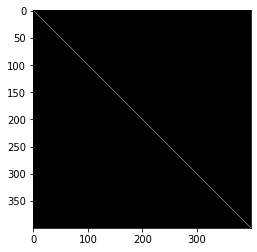

In [ ]:
M1 = np.eye((400))
# no le da el formato correcto a las imagenes
plt.imshow(M1)
plt.gray()

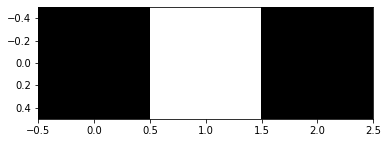

In [ ]:
M2 = np.array([[0], [1], [0]])
# transpose es para invertir la matriz
plt.imshow(M2.transpose())

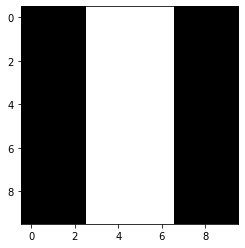

In [ ]:
# 10x10
l1 = np.zeros((3, 10))
l2 = np.ones((4, 10))
l3 = np.zeros((3, 10))
result = np.concatenate((l1, l2, l3))
plt.imshow(result.transpose())

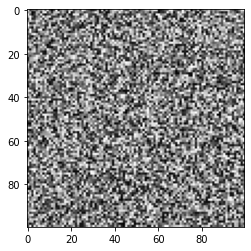

In [ ]:
# Ruido
M3 = np.random.rand(100, 100)
plt.imshow(M3)

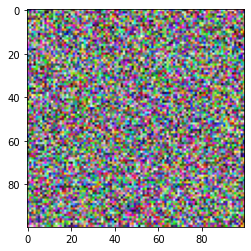

In [ ]:
# Ruido a colores
M4 = np.random.rand(100, 100, 3)
#                    f    c   d
plt.imshow(M4)

In [ ]:
# inicializar la variable de la imagen
Bandera = np.zeros((3, 3, 3))
#                   f  c  d
print(Bandera)

[[[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


[[[255.   0.   0.]
  [255.   0.   0.]
  [255.   0.   0.]]

 [[255. 255. 255.]
  [255. 255. 255.]
  [255. 255. 255.]]

 [[255.   0.   0.]
  [255.   0.   0.]
  [255.   0.   0.]]]


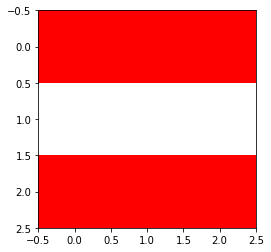

In [ ]:
Rojo = np.array([255, 0, 0])
Verde = np.array([255, 255, 255])
Azul =np.array([255, 0, 0])
Bandera[:][:][0] = Rojo
Bandera[:][:][1] = Verde
Bandera[:][:][2] = Azul
print(Bandera)
plt.imshow(Bandera)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


[[[255.   0.   0.]
  [255. 255. 255.]
  [255.   0.   0.]]

 [[255.   0.   0.]
  [255. 255. 255.]
  [255.   0.   0.]]

 [[255.   0.   0.]
  [255. 255. 255.]
  [255.   0.   0.]]]


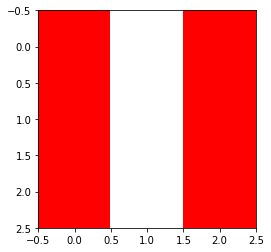

In [ ]:
# transpose(posiciones del array 3d)
voltear = Bandera.transpose(1, 0, 2)
print(voltear)
plt.imshow(voltear)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


[[[255. 255.   0.]
  [  0.   0.   0.]
  [  0.   0. 255.]]

 [[  0. 255. 255.]
  [255. 255. 255.]
  [128. 128. 128.]]

 [[128.   0.   0.]
  [  0. 255.   0.]
  [255.   0. 255.]]]


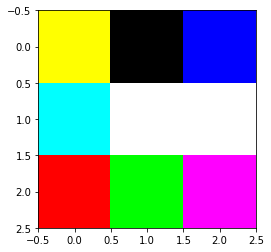

In [ ]:
#Inicializar la imagen
RGB = np.zeros((3,3,3))
R = np.array([[255, 255, 0],[0, 0, 0], [0, 0, 255]])
G = np.array([[0, 255, 255], [255, 255, 255], [128, 128, 128]])
B = np.array([[128, 0, 0], [0, 255, 0], [255, 0, 255]])
RGB[:][:][0] = R
RGB[:][:][1] = G
RGB[:][:][2] = B
print(RGB)
plt.imshow(RGB)

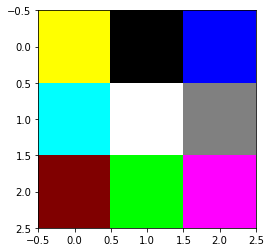

In [ ]:
#Las imagenes tienen un formato de 8 bits o 1 byte
#Los valores son 0 a 255
#Transformar la imagen a ese formato uint8 (0 - 255)
RGB_uint8 = RGB.astype(np.uint8)
plt.imshow(RGB_uint8)

**ADQUISICIÓN DE IMÁGENES**

In [ ]:
# OpenCV
import cv2
# mostrar imagenes
from google.colab.patches import cv2_imshow

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 34174  100 34174    0     0  28549      0  0:00:01  0:00:01 --:--:-- 28573


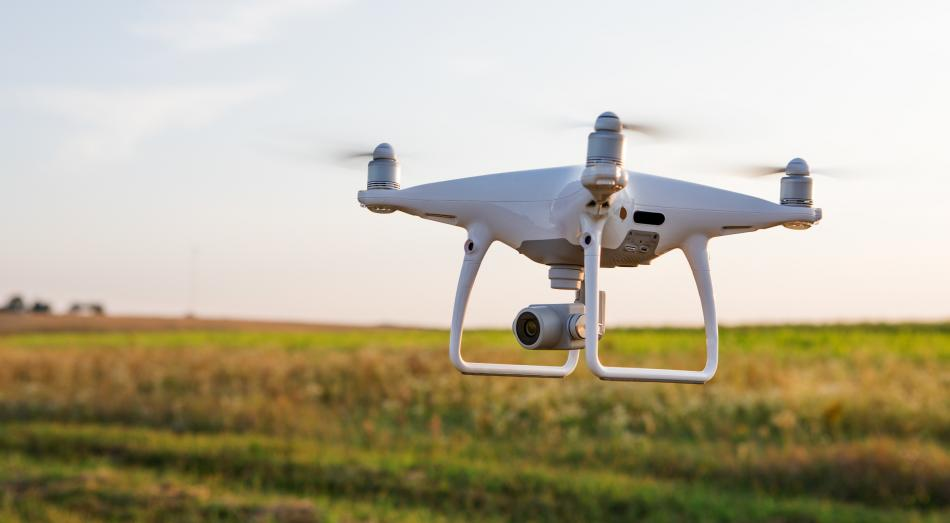

In [ ]:
!curl -o imagen https://cdn.computerhoy.com/sites/navi.axelspringer.es/public/styles/950/public/media/image/2021/04/drone-2308279.jpg?itok=X4UA6iQq
img = cv2.imread("imagen")
cv2_imshow(img)

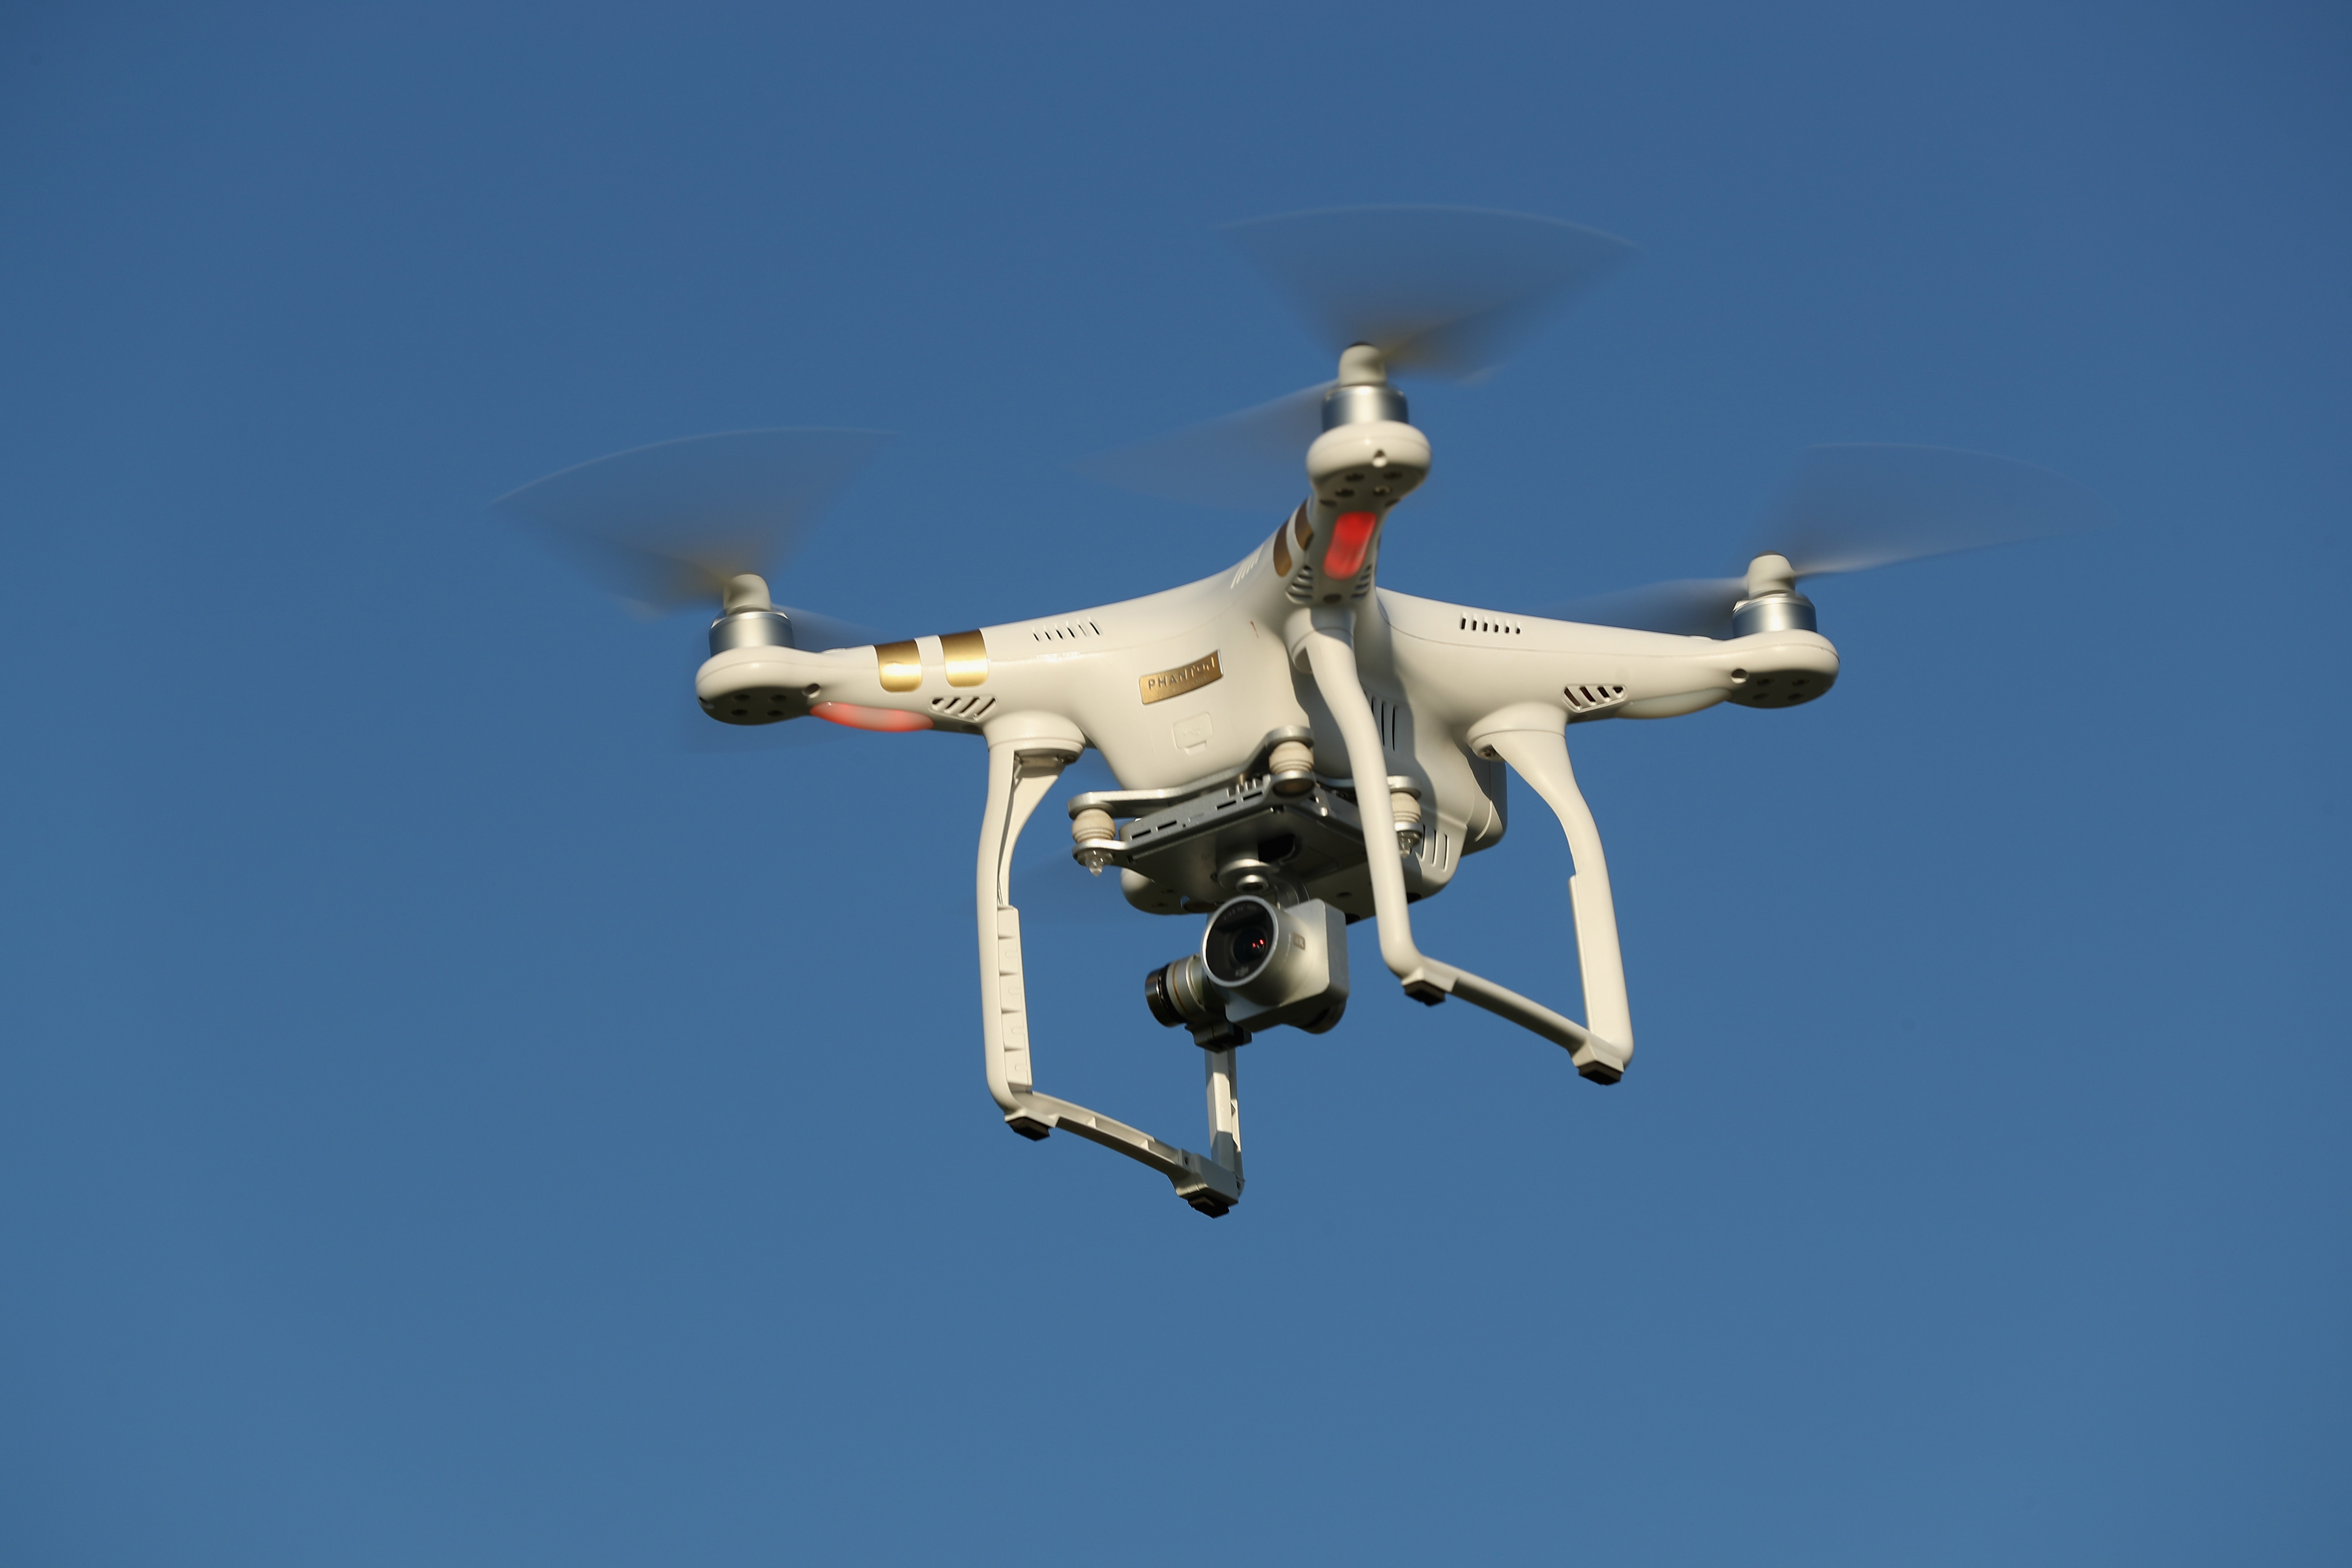

In [ ]:
imagen_dron = cv2.imread("drone.jpg")
cv2_imshow(imagen_dron)

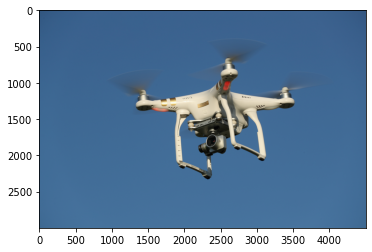

In [ ]:
imagen_dron_rgb = cv2.cvtColor(imagen_dron, cv2.COLOR_BGR2RGB)
plt.imshow(imagen_dron_rgb)

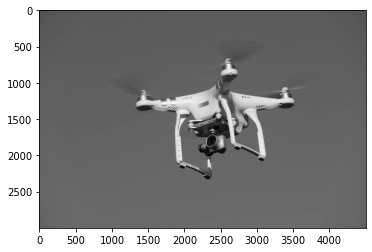

In [ ]:
#RGB a gris utilizando openCV
imagen_gris = cv2.cvtColor(imagen_dron, cv2.COLOR_BGR2GRAY)
plt.imshow(imagen_gris)

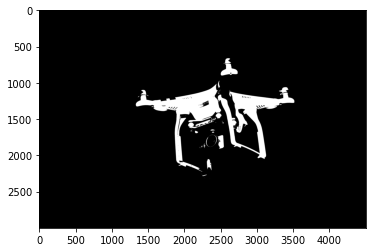

In [ ]:
#Gris a binario utilizando OpenCV
umbral = 128
#Tupla (valor1, valor2): valor1 = umbral1, valo2 = matriz binaria
(_, imagen_binaria) = cv2.threshold(imagen_gris, umbral, 255, cv2.THRESH_BINARY)
plt.imshow(imagen_binaria)

In [ ]:
imagen_dron.shape

(3000, 4500, 3)

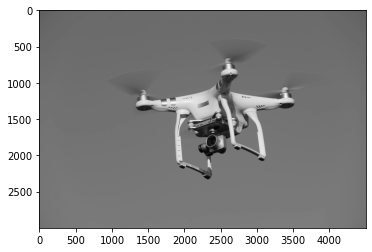

In [ ]:
(f, c, d) = imagen_dron.shape
if d == 3:
  R = imagen_dron[:,:,0]
  G = imagen_dron[:,:,1]
  B = imagen_dron[:,:,2]
  imagen_dron_gris = 0.299*R + 0.587*G + 0.114*B
  plt.imshow(imagen_dron_gris)

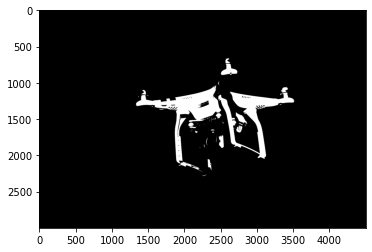

In [ ]:
imagen_dron_binario = imagen_dron_gris > 150
plt.imshow(imagen_dron_binario)

In [ ]:
def ConvertRGB2Gray(imagen_rgb):
  (f, c, d) = imagen_rgb.shape
  if d == 3:
    R = imagen_rgb[:,:,0]
    G = imagen_rgb[:,:,1]
    B = imagen_rgb[:,:,2]
    imagen_rgb_gris = 0.299*R + 0.587*G + 0.114*B
    return imagen_rgb_gris

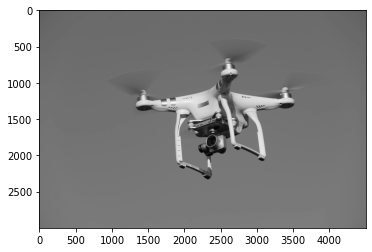

In [ ]:
imagen_dron_gris2 = ConvertRGB2Gray(imagen_dron)
plt.imshow(imagen_dron_gris2)

In [ ]:
from RGB2Gray import ConvertRGB2Gray2
imagen_dron_gris_nueva = ConvertRGB2Gray2(imagen_dron)
# plt.imshow(imagen_dron_gris_nueva)

ModuleNotFoundError: ignored